## Library and Output Loading

In [1]:
#### Loading Libraries

from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (accuracy_score,precision_score,recall_score,balanced_accuracy_score,
f1_score,confusion_matrix,roc_curve,roc_auc_score)

PROJECT_ROOT = Path.cwd().parents[3]

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from utils.experiment_utils.output_manager import (get_latest_output_csv)

TASK = "detection"
DATASET = "deal-300k"
MODEL = "b-free"
EXPERIMENT = "experiment1"

#### Loading Output CSV

experiment_file = (PROJECT_ROOT/ "experiments-pipeline"/ TASK/ DATASET/ MODEL/ f"{EXPERIMENT}.py")
latest_csv = get_latest_output_csv(experiment_file)
if latest_csv is None:
    raise FileNotFoundError("No output CSV found for {EXPERIMENT}.")

print(f"Using output file:\n{latest_csv}")
results_df = pd.read_csv(latest_csv)
display(results_df.head())

Using output file:
/Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/outputs/detection/deal-300k/b-free/experiment1_deal-300k_b-free_20260814_042708.csv


,run_timestamp,image_id,file_name,label,image_path,image_height,image_width,score,inference_time_ms,inference_status,error_type,error_message
0,2026-08-14 04:27:10,real_000000000322,000000000322.jpg,0,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...,448,576,0.199955,966.421500,SUCCESS,NaN,NaN
1,2026-08-14 04:27:10,real_000000000419,000000000419.jpg,0,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...,384,512,0.013299,1070.455500,SUCCESS,NaN,NaN
2,2026-08-14 04:27:10,real_000000000757,000000000757.jpg,0,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...,384,512,0.008745,1119.146250,SUCCESS,NaN,NaN
3,2026-08-14 04:27:10,real_000000001063,000000001063.jpg,0,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...,512,384,0.001771,1090.292875,SUCCESS,NaN,NaN
4,2026-08-14 04:27:10,real_000000001138,000000001138.jpg,0,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...,384,512,0.011600,1027.646917,SUCCESS,NaN,NaN


## File pre-processing

In [2]:
##### Separating SUCCESS and FAILED Cases

successful_df = (results_df[results_df["inference_status"] == "SUCCESS"].copy())
failed_df = (results_df[results_df["inference_status"] == "FAILED"].copy())

print("=" * 70)
print("Inference Summary")
print("=" * 70)

print(f"Latest CSV           : {latest_csv.name}")
print(f"Total Images         : {len(results_df)}")
print(f"Successful           : {len(successful_df)}")
print(f"Failed               : {len(failed_df)}")

Inference Summary
Latest CSV           : experiment1_deal-300k_b-free_20260814_042708.csv
Total Images         : 7000
Successful           : 7000
Failed               : 0


## Metrics

In [3]:
#### Accuracy, Precision, Recall and F1

THRESHOLD = 0.5

y_true = successful_df["label"].astype(int)

y_score = successful_df["score"].astype(float)

y_pred = (y_score >= THRESHOLD).astype(int)

accuracy = accuracy_score(y_true, y_pred)

balanced_accuracy = balanced_accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0,
)

metrics_df = pd.DataFrame(
    {
        "Metric": [
            "Accuracy",
            "Balanced Accuracy",
            "Precision",
            "Recall",
            "F1 Score",
        ],
        "Value": [
            accuracy,
            balanced_accuracy,
            precision,
            recall,
            f1,
        ],
    }
)

display(metrics_df)

,Metric,Value
0,Accuracy,0.986714
1,Balanced Accuracy,0.986714
2,Precision,0.977305
3,Recall,0.996571
4,F1 Score,0.986844


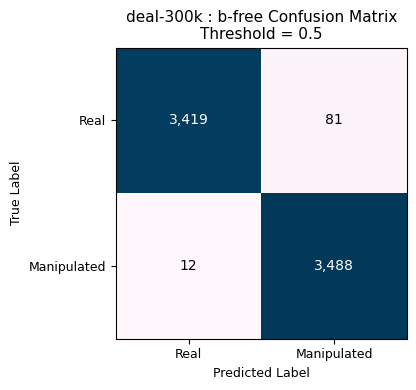

In [4]:
#### Confusion Matrix

cm = confusion_matrix(y_true,y_pred,labels=[0, 1])
plt.figure(figsize=(5, 4))
plt.imshow(cm,cmap="PuBu")

plt.title(
    f"{DATASET} : {MODEL} Confusion Matrix\n"
    f"Threshold = {THRESHOLD}", fontsize = 11)

plt.xlabel("Predicted Label", fontsize = 9)
plt.ylabel("True Label", fontsize = 9)

plt.xticks([0, 1],["Real", "Manipulated"],fontsize = 9)
plt.yticks([0, 1],["Real", "Manipulated"],fontsize = 9)

# Display Cell Values
threshold_value = cm.max() / 2
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):

        plt.text(
            j,
            i,
            f"{cm[i, j]:,}",
            ha="center",
            va="center",
            color=(
                "white"
                if cm[i, j] > threshold_value
                else "black"
            ),
        )


plt.tight_layout()
plt.show()

deal-300k ROC - AUC Analysis
AUC Score : 0.9996


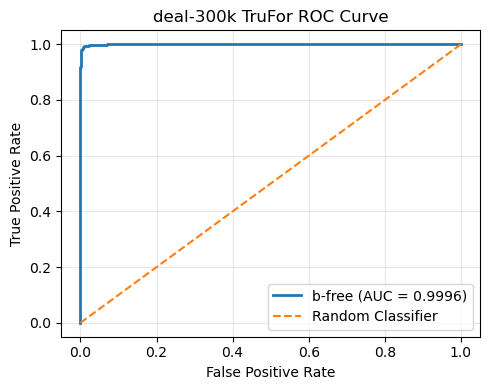

In [5]:
#### ROC - AUC Characteristics

from sklearn.metrics import (roc_curve,roc_auc_score)

 
# Compute ROC and AUC
fpr, tpr, thresholds = roc_curve(y_true,y_score)
auc_score = roc_auc_score(y_true,y_score)

 
# Display AUC
print("=" * 70)
print(f"{DATASET} ROC - AUC Analysis")
print("=" * 70)

print(f"AUC Score : {auc_score:.4f}")


 
# ROC Curve
plt.figure(figsize=(5, 4))
plt.plot(fpr,tpr,linewidth=2,label=f"{MODEL} (AUC = {auc_score:.4f})")
plt.plot([0, 1],[0, 1],linestyle="--",linewidth=1.5,label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title( f"{DATASET} TruFor ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Output Analysis

### Helper Functions

In [6]:
def get_performance_subsets(df,n=4,threshold=0.5,):
    """
    Select best, worst, and borderline samples from an experiment DataFrame.

    Each returned dictionary has the form:

        {
            "real": [
                (image_path, score),
                ...
            ],
            "fake": [
                (image_path, score),
                ...
            ]
        }

    Parameters
    ----------
    df : pandas.DataFrame
        Experiment output DataFrame.

    n : int, default=4
        Number of samples to select per class.

    threshold : float, default=0.5
        Detection decision threshold.

    Returns
    -------
    tuple[dict, dict, dict]
        best, worst, borderline
    """

    required_columns = {
        "image_path",
        "label",
        "score",
        "inference_status",
    }

    missing = required_columns - set(df.columns)

    if missing:
        raise ValueError(
            f"Missing required columns: {sorted(missing)}"
        )

    # --------------------------------------------------------
    # Successful inferences only
    # --------------------------------------------------------

    df = df[df["inference_status"] == "SUCCESS"].copy()

    if df.empty:
        raise ValueError(
            "No successful inferences found."
        )

    # --------------------------------------------------------
    # Ensure numeric values
    # --------------------------------------------------------

    df["score"] = pd.to_numeric(
        df["score"],
        errors="coerce",
    )

    df["label"] = pd.to_numeric(
        df["label"],
        errors="coerce",
    )

    df = df.dropna(
        subset=["image_path", "score", "label"]
    )

    # --------------------------------------------------------
    # Split real / fake
    # --------------------------------------------------------

    real = df[df["label"] == 0].copy()
    fake = df[df["label"] == 1].copy()

    # --------------------------------------------------------
    # Best
    #
    # Real -> score closest to 0
    # Fake -> score closest to 1
    # --------------------------------------------------------

    best_real = (
        real.sort_values("score", ascending=True)
        .head(n)
    )

    best_fake = (
        fake.sort_values("score", ascending=False)
        .head(n)
    )

    best = {
        "real": list(
            zip(
                best_real["image_path"],
                best_real["score"],
            )
        ),
        "fake": list(
            zip(
                best_fake["image_path"],
                best_fake["score"],
            )
        ),
    }

    # --------------------------------------------------------
    # Worst
    #
    # Real -> score closest to 1
    # Fake -> score closest to 0
    # --------------------------------------------------------

    worst_real = (
        real.sort_values("score", ascending=False)
        .head(n)
    )

    worst_fake = (
        fake.sort_values("score", ascending=True)
        .head(n)
    )

    worst = {
        "real": list(
            zip(
                worst_real["image_path"],
                worst_real["score"],
            )
        ),
        "fake": list(
            zip(
                worst_fake["image_path"],
                worst_fake["score"],
            )
        ),
    }

    # --------------------------------------------------------
    # Borderline
    #
    # Closest to the decision threshold.
    # --------------------------------------------------------

    real["threshold_distance"] = (
        real["score"] - threshold
    ).abs()

    fake["threshold_distance"] = (
        fake["score"] - threshold
    ).abs()

    borderline_real = (
        real.sort_values(
            "threshold_distance",
            ascending=True,
        )
        .head(n)
    )

    borderline_fake = (
        fake.sort_values(
            "threshold_distance",
            ascending=True,
        )
        .head(n)
    )

    borderline = {
        "real": list(
            zip(
                borderline_real["image_path"],
                borderline_real["score"],
            )
        ),
        "fake": list(
            zip(
                borderline_fake["image_path"],
                borderline_fake["score"],
            )
        ),
    }

    return best, worst, borderline

In [7]:
import matplotlib.pyplot as plt
from PIL import Image


def _format_score(score):
    """
    Format prediction score for visualization.

    Scores close to 0 or 1 are displayed in scientific notation
    to avoid hiding their actual values through rounding.
    """
    score = float(score)

    if score < 0.01 or score > 0.99:
        return f"{score:.3e}"

    return f"{score:.2f}"


def visualize_prediction_samples(samples):
    """
    Visualize real and fake samples in a 2x4 grid.

    Parameters
    ----------
    samples : dict
        Dictionary with the structure:

        {
            "real": [
                (image_path, score),
                ...
            ],
            "fake": [
                (image_path, score),
                ...
            ]
        }

    Layout
    ------
    Row 1 -> Real images
    Row 2 -> Fake images
    """

    fig, axes = plt.subplots(
        2,
        4,
        figsize=(16, 8)
    )

    row_labels = ["Real", "Fake"]

    for row, label in enumerate(["real", "fake"]):

        samples_for_class = samples.get(label, [])

        for col in range(4):

            ax = axes[row, col]

            # Handle missing samples
            if col >= len(samples_for_class):
                ax.axis("off")
                continue

            image_path, score = samples_for_class[col]

            try:
                image = Image.open(image_path).convert("RGB")

                ax.imshow(image)

                ax.set_title(
                    f"Score: {_format_score(score)}",
                    fontsize=12
                )

                ax.axis("off")

            except Exception as e:
                ax.axis("off")
                ax.set_title(
                    f"Error\n{type(e).__name__}",
                    fontsize=10
                )

        # Explicit row label
        axes[row, 0].annotate(
            row_labels[row],
            xy=(-0.12, 0.5),
            xycoords="axes fraction",
            fontsize=14,
            fontweight="bold",
            ha="right",
            va="center",
            rotation=90
        )

    # Leave space on the left for row labels
    plt.tight_layout(rect=[0.04, 0, 1, 1])

    plt.show()

In [8]:
best, worst, borderline = get_performance_subsets(results_df,n=4,threshold=0.5)

### Best Performance

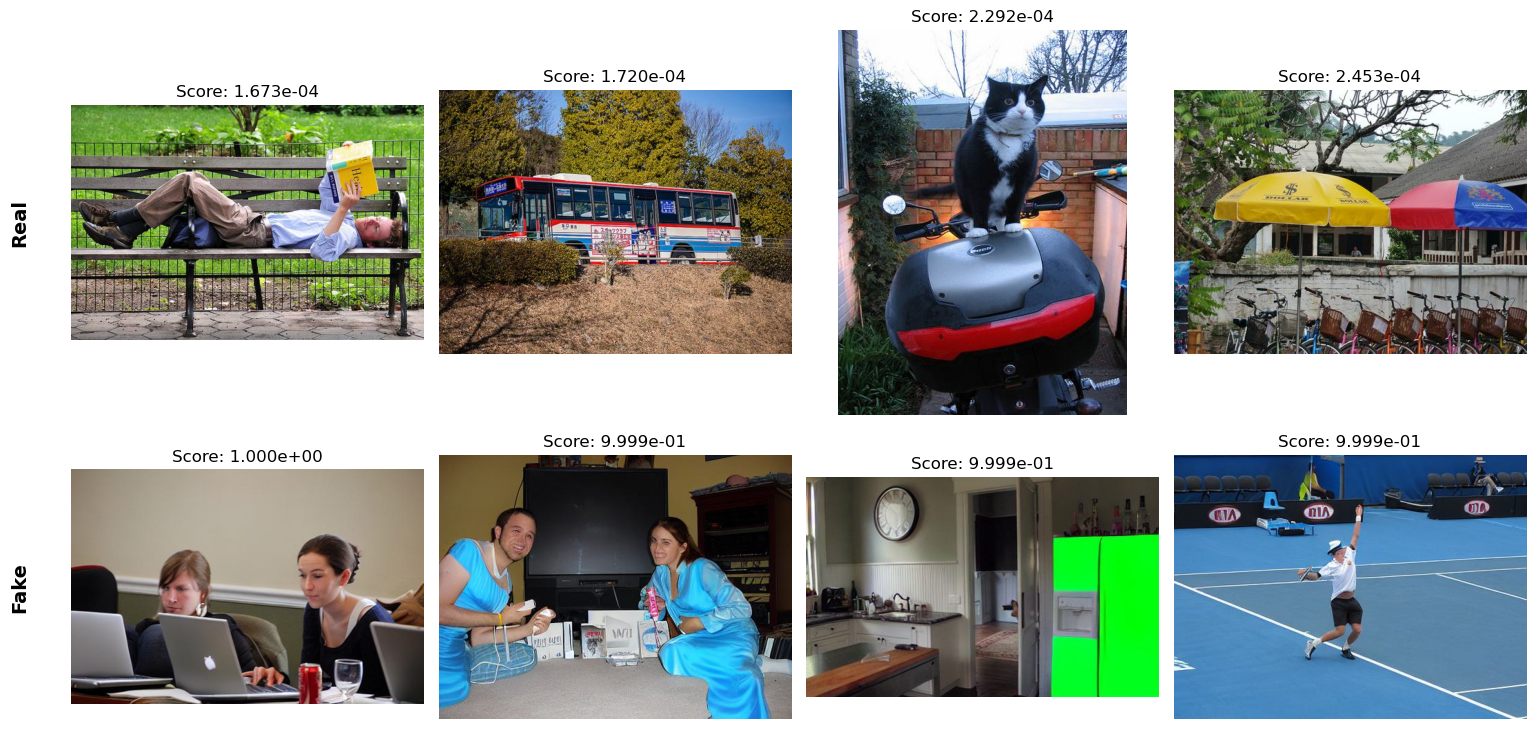

In [9]:
visualize_prediction_samples(best)

### Worst Performance

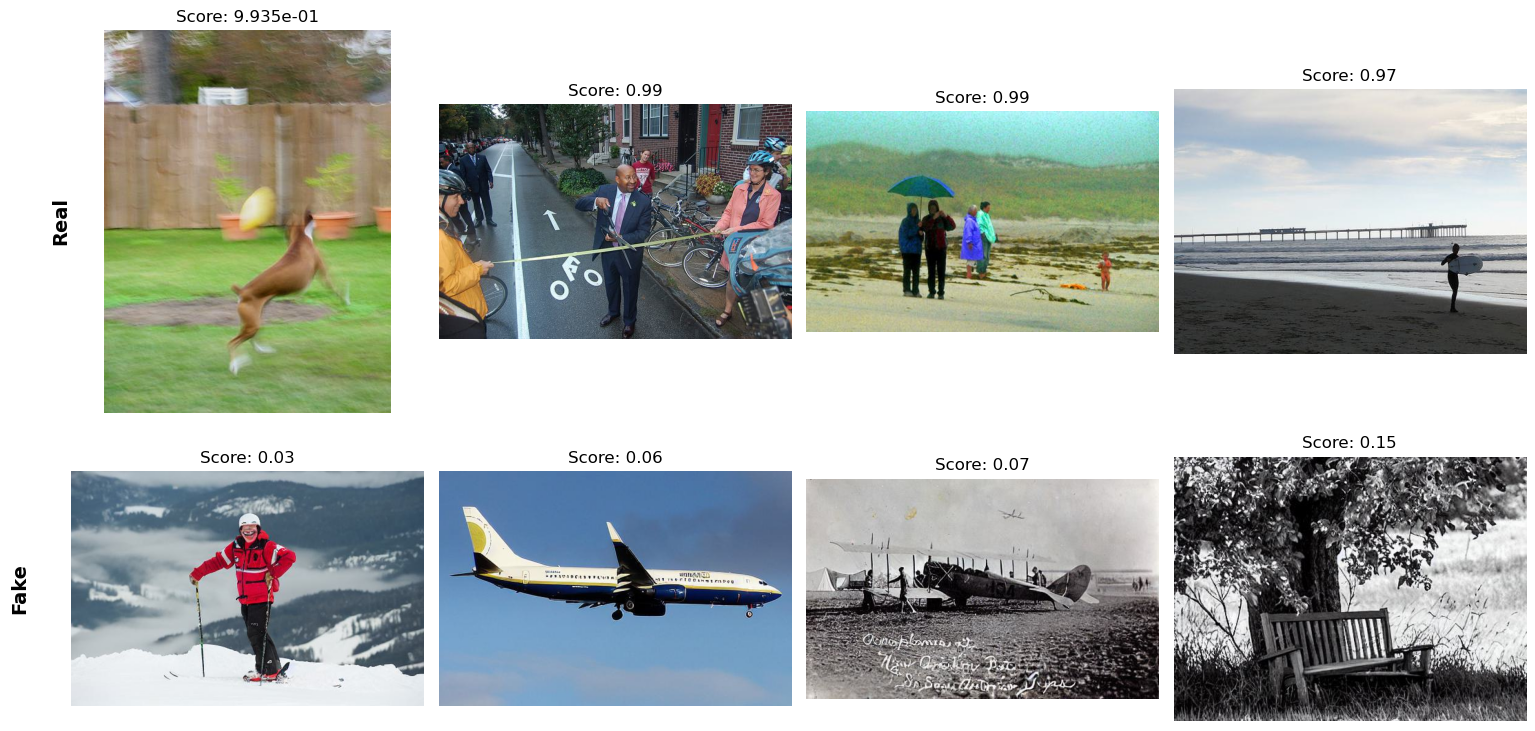

In [10]:
visualize_prediction_samples(worst)

### Borderline Performance

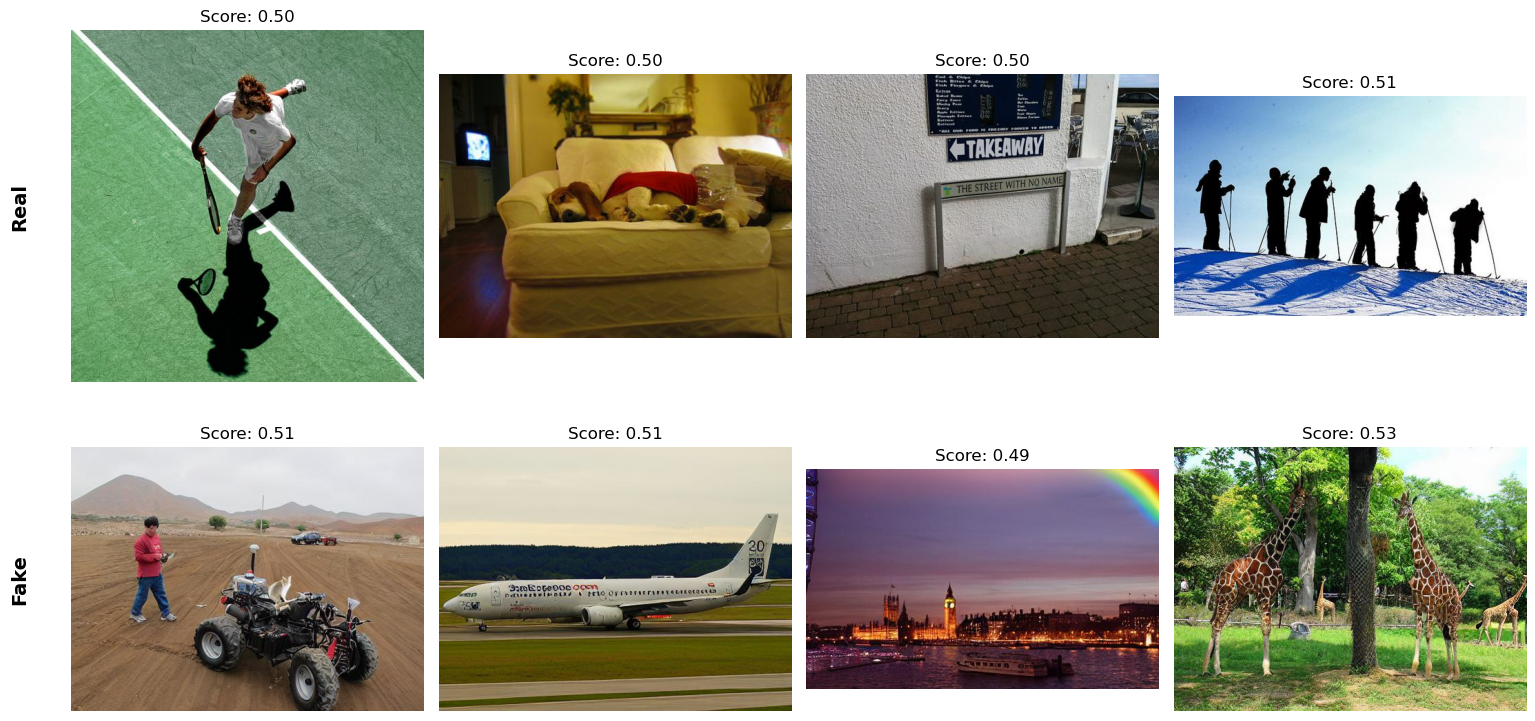

In [11]:
visualize_prediction_samples(borderline)

## Saving Misclassifications

In [ ]:
from pathlib import Path
import math

import pandas as pd
from PIL import Image, ImageDraw, ImageFont


def save_classification_analysis(
    results_df,
    task,
    dataset,
    model,
    experiment,
    project_root,
    threshold=0.5,
    correct_percentile=0.70,
):
    """
    Save correctly classified and misclassified samples.

    Output structure
    ----------------
    outputs/
        <task>/
            <dataset>/
                <model>/
                    classification_analysis/
                        misclassifications/
                            real/
                            edited/
                            misclassifications.csv

                        correctly_classified/
                            real/
                            edited/
                            correctly_classified.csv

    Misclassifications
    ------------------
    False positives:
        GT = Real
        Pred = Edited
        Sorted by descending score.

    False negatives:
        GT = Edited
        Pred = Real
        Sorted by ascending score.

    Correct classifications
    -----------------------
    True negatives:
        GT = Real
        Pred = Real
        Sorted by ascending score.

    True positives:
        GT = Edited
        Pred = Edited
        Sorted by descending score.

    Only the first `correct_percentile` fraction of correctly
    classified samples in each class is saved.

    Each saved image contains a separate metadata header above
    the original image. The original image pixels are untouched.

    Parameters
    ----------
    results_df : pandas.DataFrame
        Experiment output DataFrame.

    task : str
        Task name.

    dataset : str
        Dataset name.

    model : str
        Model name.

    experiment : str
        Experiment name.

    project_root : str or Path
        Project root directory.

    threshold : float, default=0.5
        Classification threshold.

    correct_percentile : float, default=0.70
        Fraction of correctly classified samples to retain.

        Example:
            100 correct samples -> 70 saved
            250 correct samples -> 175 saved

    Returns
    -------
    tuple[pandas.DataFrame, pandas.DataFrame]
        (
            misclassification_df,
            correctly_classified_df
        )
    """

    project_root = Path(project_root).resolve()

    # ========================================================
    # Validate required columns
    # ========================================================

    required_columns = {
        "image_id",
        "file_name",
        "label",
        "image_path",
        "score",
        "inference_status",
    }

    missing_columns = required_columns - set(results_df.columns)

    if missing_columns:
        raise ValueError(
            "Missing required columns in results_df: "
            f"{sorted(missing_columns)}"
        )

    # ========================================================
    # Successful inferences only
    # ========================================================

    df = results_df[
        results_df["inference_status"]
        .astype(str)
        .str.upper()
        == "SUCCESS"
    ].copy()

    if df.empty:
        raise ValueError(
            "No successful inferences found in results_df."
        )

    # ========================================================
    # Numeric conversion
    # ========================================================

    df["label"] = pd.to_numeric(
        df["label"],
        errors="coerce",
    )

    df["score"] = pd.to_numeric(
        df["score"],
        errors="coerce",
    )

    df = df.dropna(
        subset=[
            "image_id",
            "image_path",
            "label",
            "score",
        ]
    )

    # ========================================================
    # Validate percentile
    # ========================================================

    if not 0 < correct_percentile <= 1:
        raise ValueError(
            "`correct_percentile` must be between 0 and 1."
        )

    # ========================================================
    # Generate predictions
    # ========================================================

    df["predicted_label"] = (
        df["score"] >= threshold
    ).astype(int)

    # ========================================================
    # Separate correctly classified / misclassified samples
    # ========================================================

    correctly_classified = df[
        df["label"] == df["predicted_label"]
    ].copy()

    false_positives = df[
        (df["label"] == 0)
        & (df["predicted_label"] == 1)
    ].copy()

    false_negatives = df[
        (df["label"] == 1)
        & (df["predicted_label"] == 0)
    ].copy()

    # ========================================================
    # MISCLASSIFICATION SORTING
    # ========================================================

    # False positives:
    # Real image predicted as Edited.
    #
    # Higher score = more confidently wrong.
    false_positives = (
        false_positives
        .sort_values(
            "score",
            ascending=False,
        )
        .reset_index(drop=True)
    )

    # False negatives:
    # Edited image predicted as Real.
    #
    # Lower score = more confidently wrong.
    false_negatives = (
        false_negatives
        .sort_values(
            "score",
            ascending=True,
        )
        .reset_index(drop=True)
    )

    # ========================================================
    # CORRECT CLASSIFICATION SORTING
    # ========================================================

    correctly_real = correctly_classified[
        correctly_classified["label"] == 0
    ].copy()

    correctly_fake = correctly_classified[
        correctly_classified["label"] == 1
    ].copy()

    # Real correctly classified:
    # Lower score = more confidently Real.
    correctly_real = (
        correctly_real
        .sort_values(
            "score",
            ascending=True,
        )
        .reset_index(drop=True)
    )

    # Edited correctly classified:
    # Higher score = more confidently Edited.
    correctly_fake = (
        correctly_fake
        .sort_values(
            "score",
            ascending=False,
        )
        .reset_index(drop=True)
    )

    # ========================================================
    # 70% CAP FOR CORRECTLY CLASSIFIED SAMPLES
    # ========================================================

    max_correct_real = math.ceil(
        len(correctly_real)
        * correct_percentile
    )

    max_correct_fake = math.ceil(
        len(correctly_fake)
        * correct_percentile
    )

    correctly_real = correctly_real.head(
        max_correct_real
    )

    correctly_fake = correctly_fake.head(
        max_correct_fake
    )

    # ========================================================
    # Output directories
    # ========================================================

    output_root = (
        project_root
        / "outputs"
        / task
        / dataset
        / model
        / "classification_analysis"
    )

    misclassification_root = (
        output_root / "misclassifications"
    )

    correct_root = (
        output_root / "correctly_classified"
    )

    misclassification_real_dir = (
        misclassification_root / "real"
    )

    misclassification_edited_dir = (
        misclassification_root / "edited"
    )

    correct_real_dir = (
        correct_root / "real"
    )

    correct_edited_dir = (
        correct_root / "edited"
    )

    for directory in [
        misclassification_real_dir,
        misclassification_edited_dir,
        correct_real_dir,
        correct_edited_dir,
    ]:
        directory.mkdir(
            parents=True,
            exist_ok=True,
        )

    # ========================================================
    # Font helpers
    # ========================================================

    def get_font(size):
        """
        Load a macOS font, with fallback to PIL default.
        """

        font_paths = [
            "/System/Library/Fonts/Helvetica.ttc",
            "/System/Library/Fonts/SFNS.ttf",
            "/Library/Fonts/Arial.ttf",
        ]

        for font_path in font_paths:
            try:
                return ImageFont.truetype(
                    font_path,
                    size,
                )
            except OSError:
                continue

        return ImageFont.load_default()

    def get_font_for_width(width):
        """
        Adapt font size according to image width.
        """

        if width >= 1200:
            size = 30
        elif width >= 800:
            size = 26
        elif width >= 600:
            size = 23
        elif width >= 400:
            size = 20
        elif width >= 300:
            size = 18
        else:
            size = 16

        return get_font(size)

    # ========================================================
    # Text wrapping
    # ========================================================

    def wrap_text_by_width(
        text,
        font,
        max_width,
        draw,
    ):
        """
        Wrap text according to rendered pixel width.
        """

        words = text.split()

        if not words:
            return [""]

        lines = []
        current_line = words[0]

        for word in words[1:]:

            candidate = (
                current_line
                + " "
                + word
            )

            bbox = draw.textbbox(
                (0, 0),
                candidate,
                font=font,
            )

            candidate_width = (
                bbox[2] - bbox[0]
            )

            if candidate_width <= max_width:
                current_line = candidate
            else:
                lines.append(current_line)
                current_line = word

        lines.append(current_line)

        # ----------------------------------------------------
        # Handle very long tokens such as image IDs.
        # ----------------------------------------------------

        final_lines = []

        for line in lines:

            bbox = draw.textbbox(
                (0, 0),
                line,
                font=font,
            )

            if (
                bbox[2] - bbox[0]
                <= max_width
            ):
                final_lines.append(line)
                continue

            current = ""

            for char in line:

                candidate = current + char

                bbox = draw.textbbox(
                    (0, 0),
                    candidate,
                    font=font,
                )

                if (
                    bbox[2] - bbox[0]
                    <= max_width
                ):
                    current = candidate
                else:

                    if current:
                        final_lines.append(
                            current
                        )

                    current = char

            if current:
                final_lines.append(current)

        return final_lines

    # ========================================================
    # Create annotated image
    # ========================================================

    def create_annotated_image(
        image_path,
        rank,
        image_id,
        true_label,
        predicted_label,
        score,
    ):
        """
        Create an image with a separate metadata header.

        The original image is never modified.
        """

        image_path = Path(image_path)

        image = Image.open(
            image_path
        ).convert("RGB")

        width, height = image.size

        font = get_font_for_width(
            width
        )

        # ----------------------------------------------------
        # Temporary drawing surface for text measurement
        # ----------------------------------------------------

        temp_canvas = Image.new(
            "RGB",
            (width, 100),
            "white",
        )

        temp_draw = ImageDraw.Draw(
            temp_canvas
        )

        horizontal_padding = 15

        max_text_width = (
            width
            - 2 * horizontal_padding
        )

        # ----------------------------------------------------
        # Score formatting
        # ----------------------------------------------------

        score = float(score)

        if score < 0.01 or score > 0.99:
            score_text = f"{score:.6e}"
        else:
            score_text = f"{score:.4f}"

        # ----------------------------------------------------
        # Metadata
        # ----------------------------------------------------

        rank_text = (
            f"Rank: {rank:06d}"
        )

        id_text = (
            f"ID: {image_id}"
        )

        gt_text = (
            "REAL"
            if true_label == 0
            else "EDITED"
        )

        pred_text = (
            "REAL"
            if predicted_label == 0
            else "EDITED"
        )

        prediction_text = (
            f"GT: {gt_text}    "
            f"Pred: {pred_text}    "
            f"Score: {score_text}"
        )

        # ----------------------------------------------------
        # Wrap image ID
        # ----------------------------------------------------

        id_lines = wrap_text_by_width(
            id_text,
            font,
            max_text_width,
            temp_draw,
        )

        # ----------------------------------------------------
        # Calculate dimensions
        # ----------------------------------------------------

        bbox = temp_draw.textbbox(
            (0, 0),
            "Ag",
            font=font,
        )

        line_height = (
            bbox[3] - bbox[1]
        )

        line_spacing = 8
        vertical_padding = 15

        total_lines = (
            1
            + len(id_lines)
            + 1
        )

        header_height = (
            (2 * vertical_padding)
            + (total_lines * line_height)
            + (
                (total_lines - 1)
                * line_spacing
            )
        )

        # ----------------------------------------------------
        # Final canvas
        # ----------------------------------------------------

        canvas = Image.new(
            "RGB",
            (
                width,
                height + header_height,
            ),
            "white",
        )

        draw = ImageDraw.Draw(
            canvas
        )

        y = vertical_padding

        # Rank
        draw.text(
            (
                horizontal_padding,
                y,
            ),
            rank_text,
            fill="black",
            font=font,
        )

        y += (
            line_height
            + line_spacing
        )

        # Image ID
        for line in id_lines:

            draw.text(
                (
                    horizontal_padding,
                    y,
                ),
                line,
                fill="black",
                font=font,
            )

            y += (
                line_height
                + line_spacing
            )

        # GT / Prediction / Score
        draw.text(
            (
                horizontal_padding,
                y,
            ),
            prediction_text,
            fill="black",
            font=font,
        )

        # ----------------------------------------------------
        # Paste original image underneath header
        # ----------------------------------------------------

        canvas.paste(
            image,
            (
                0,
                header_height,
            ),
        )

        return canvas

    # ========================================================
    # Save samples
    # ========================================================

    def save_samples(
        dataframe,
        output_directory,
        classification_name,
    ):
        """
        Save images and return manifest rows.
        """

        manifest_rows = []

        for index, row in dataframe.iterrows():

            rank = index + 1

            source_path = Path(
                row["image_path"]
            )

            if not source_path.exists():

                print(
                    "Warning: image not found, "
                    f"skipping:\n{source_path}"
                )

                continue

            annotated_image = (
                create_annotated_image(
                    image_path=source_path,
                    rank=rank,
                    image_id=row["image_id"],
                    true_label=int(
                        row["label"]
                    ),
                    predicted_label=int(
                        row["predicted_label"]
                    ),
                    score=float(
                        row["score"]
                    ),
                )
            )

            # ------------------------------------------------
            # Preserve original extension
            # ------------------------------------------------

            extension = (
                source_path.suffix.lower()
            )

            if not extension:
                extension = ".jpg"

            destination = (
                output_directory
                / f"{rank:06d}{extension}"
            )

            annotated_image.save(
                destination
            )

            manifest_rows.append(
                {
                    "rank": rank,
                    "image_id": row["image_id"],
                    "file_name": row["file_name"],
                    "true_label": int(
                        row["label"]
                    ),
                    "predicted_label": int(
                        row["predicted_label"]
                    ),
                    "score": float(
                        row["score"]
                    ),
                    "threshold": threshold,
                    "distance_from_threshold": abs(
                        float(row["score"])
                        - threshold
                    ),
                    "classification": (
                        classification_name
                    ),
                    "original_image_path": str(
                        source_path
                    ),
                    "saved_image_path": str(
                        destination
                    ),
                }
            )

        return manifest_rows

    # ========================================================
    # Save misclassifications
    # ========================================================

    misclassification_rows = []

    misclassification_rows.extend(
        save_samples(
            dataframe=false_positives,
            output_directory=(
                misclassification_real_dir
            ),
            classification_name=(
                "false_positive"
            ),
        )
    )

    misclassification_rows.extend(
        save_samples(
            dataframe=false_negatives,
            output_directory=(
                misclassification_edited_dir
            ),
            classification_name=(
                "false_negative"
            ),
        )
    )

    # ========================================================
    # Save correctly classified samples
    # ========================================================

    correct_rows = []

    correct_rows.extend(
        save_samples(
            dataframe=correctly_real,
            output_directory=(
                correct_real_dir
            ),
            classification_name=(
                "true_negative"
            ),
        )
    )

    correct_rows.extend(
        save_samples(
            dataframe=correctly_fake,
            output_directory=(
                correct_edited_dir
            ),
            classification_name=(
                "true_positive"
            ),
        )
    )

    # ========================================================
    # Create manifest DataFrames
    # ========================================================

    misclassification_df = pd.DataFrame(
        misclassification_rows
    )

    correctly_classified_df = pd.DataFrame(
        correct_rows
    )

    # ========================================================
    # Save manifests
    # ========================================================

    misclassification_manifest = (
        misclassification_root
        / "misclassifications.csv"
    )

    correctly_classified_manifest = (
        correct_root
        / "correctly_classified.csv"
    )

    misclassification_df.to_csv(
        misclassification_manifest,
        index=False,
    )

    correctly_classified_df.to_csv(
        correctly_classified_manifest,
        index=False,
    )

    # ========================================================
    # Summary
    # ========================================================

    print("=" * 70)
    print("Classification Analysis")
    print("=" * 70)

    print(f"Experiment : {experiment}")
    print(f"Dataset    : {dataset}")
    print(f"Model      : {model}")
    print(f"Threshold  : {threshold}")
    print()

    print("Misclassifications")
    print(
        f"  False Positives : "
        f"{len(false_positives)}"
    )
    print(
        f"  False Negatives : "
        f"{len(false_negatives)}"
    )

    print()

    print("Correctly Classified")
    print(
        f"  Real retained   : "
        f"{len(correctly_real)}"
    )
    print(
        f"  Edited retained : "
        f"{len(correctly_fake)}"
    )

    print()

    print(
        f"Output directory : "
        f"{output_root}"
    )

    print(
        f"Misclassification manifest : "
        f"{misclassification_manifest}"
    )

    print(
        f"Correct classification manifest : "
        f"{correctly_classified_manifest}"
    )

    return (
        misclassification_df,
        correctly_classified_df,
    )

In [ ]:
misclassification_df, correctly_classified_df = (
    save_classification_analysis(
        results_df=results_df,
        task=TASK,
        dataset=DATASET,
        model=MODEL,
        experiment=EXPERIMENT,
        project_root=PROJECT_ROOT,
        threshold=0.5,
        correct_percentile=0.75,
    )
)

Classification Analysis
Experiment : experiment1
Dataset    : br-gen
Model      : b-free
Threshold  : 0.5

Misclassifications
  False Positives : 22
  False Negatives : 665

Correctly Classified
  Real retained   : 1109
  Edited retained : 1752

Output directory : /Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/outputs/detection/br-gen/b-free/classification_analysis
Misclassification manifest : /Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/outputs/detection/br-gen/b-free/classification_analysis/misclassifications/misclassifications.csv
Correct classification manifest : /Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/outputs/detection/br-gen/b-free/classification_analysis/correctly_classified/correctly_classified.csv
